# WiPER Benchmarking — v9: fase e "vuoto"

Notebook autonomo, stesso protocollo di v7/v8 (k-fold sulle identità, 4 protocolli per registrazione, chance esatta, selezione annidata).

**Dati in ingresso** (prodotti da *WiPER-DataProcessing*, nessuna modifica necessaria):
* `output/CSV/<sanitization>/...` → ampiezze (come in v8, quindi le righe solo-ampiezza sono confrontabili con v8)
* `output/CSV/csi_matrices/` → CSI **complesso** (reale + j·immaginario) da cui si ricava la **fase**

**Cosa aggiunge**

| # | Contenuto |
|---|---|
| 1 | **Sanitizzazione della fase per pacchetto** (srotolamento sulle sottoportanti + rimozione di offset e pendenza lineare; modalità `'offset'` = solo offset). Il CSI grezzo ha un offset di fase casuale per pacchetto (~1.8 rad) che va tolto prima di ogni statistica |
| 2 | Nuovi gruppi di feature: `ph_static`, `ph_std`, `ph_diff` (fase residua) e `ph_sto` (pendenza/offset per pacchetto: **solo diagnostica**, è un indicatore dell'hardware/sessione, non della persona) |
| 3 | **"Vuoto" come sottrazione complessa**: `|H_san − H_vuoto|` (componente di canale dovuta al corpo). Con feature standardizzate una sottrazione *costante* sulle ampiezze non cambia nulla (lo si verifica nella cella dedicata); la sottrazione sul campo complesso è invece non lineare |
| 4 | Ablazione ampiezza / fase / vuoto, **controllo di deriva** per ogni gruppo, localizzazione degli errori, confronto `linear` vs `offset`, selezione annidata della configurazione |
| 5 | Esporta le fasi sanitizzate in `output/CSV/sanitized_phases/` (stesso formato dei CSV delle ampiezze) per usarle nella GNN/DatasetGeneration |

> Convenzione del processing: `H = primo_valore + j·secondo_valore`. Se il dispositivo emette (immaginario, reale) la fase risulta riflessa (π/2 − φ): dopo la rimozione dell'offset cambia solo il segno, nessun effetto sul riconoscimento.

## 1. Imports e configurazione

In [1]:
import os, re, random, time
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import rankdata
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

pd.set_option('display.max_columns', None); pd.set_option('display.width', 250)

CFG = dict(
    seed=42,
    output_folder='./output/',
    sanitization='zscore',            # ampiezze: 'raw' | 'hampel' | 'zscore' | 'iqr' (come DatasetGeneration v4)
    exclude_ids=('vuoto',),
    gallery_action='saluto', probe_action='tpose',
    n_subcarriers=52,
    # --- fase ---
    phase_mode='linear',              # 'linear' = via offset+pendenza per pacchetto | 'offset' = via solo l'offset
    phase_outlier_z=3.0,              # |z|>soglia (per sottoportante) -> sostituito (ffill/bfill); None = nessun filtro
    export_phase_csv=True,            # scrive output/CSV/sanitized_phases/<mode>_phases/
    # --- CV ---
    n_folds=4, inner_folds=3,
    drift_perms=2000,
)

SANITIZATION_DIRS = {
    'raw':    ('CSV', 'raw_amplitudes'),
    'hampel': ('CSV', 'sanitized_amplitudes', 'HF_amplitudes'),
    'zscore': ('CSV', 'sanitized_amplitudes', 'zscore_amplitudes'),
    'iqr':    ('CSV', 'sanitized_amplitudes', 'iqr_amplitudes'),
}
amp_dir = os.path.join(CFG['output_folder'], *SANITIZATION_DIRS[CFG['sanitization']])
csi_dir = os.path.join(CFG['output_folder'], 'CSV', 'csi_matrices')
random.seed(CFG['seed']); np.random.seed(CFG['seed'])
print('ampiezze:', amp_dir, '\nCSI complesso:', csi_dir)

ampiezze: ./output/CSV/sanitized_amplitudes/zscore_amplitudes 
CSI complesso: ./output/CSV/csi_matrices


## 2. Caricamento: ampiezze + CSI complesso + registrazioni "vuoto"

In [2]:
KEY_RE = re.compile(r'^(?P<sid>[^_]+)_(?P<act>[A-Za-z]+)(?P<num>\d+)$')
assert os.path.isdir(amp_dir), f'Cartella non trovata: {amp_dir}'
assert os.path.isdir(csi_dir), f'Cartella non trovata: {csi_dir} (la crea WiPER-DataProcessing: output/CSV/csi_matrices)'

def load_amp(key):
    return pd.read_csv(os.path.join(amp_dir, key + '.csv')).drop(columns='timestamp', errors='ignore').to_numpy(dtype=np.float64)

def load_csi(key):
    # le matrici complesse sono salvate come stringhe '(21-3j)'
    df = pd.read_csv(os.path.join(csi_dir, key + '.csv')).drop(columns='timestamp', errors='ignore')
    return df.to_numpy().astype(str).astype(complex)

recs, vuoto = [], []
for fname in sorted(os.listdir(amp_dir)):
    if not fname.endswith('.csv'): continue
    key = fname[:-4]
    if key.split('_')[0] in CFG['exclude_ids']:
        vuoto.append(dict(rec_id=key, A=load_amp(key), H=load_csi(key))); continue
    m = KEY_RE.match(key)
    if not m: print('ignorato:', key); continue
    A, H = load_amp(key), load_csi(key)
    assert A.shape == H.shape == (A.shape[0], CFG['n_subcarriers']), f'{key}: forme incoerenti {A.shape} vs {H.shape}'
    recs.append(dict(sid=m.group('sid'), act=m.group('act').lower(), num=int(m.group('num')), rec_id=key, A=A, H=H))

R = len(recs)
rec_sid = np.array([r['sid'] for r in recs]); rec_act = np.array([r['act'] for r in recs])
GAL, PRB = CFG['gallery_action'], CFG['probe_action']
assert GAL in set(rec_act) and PRB in set(rec_act)
lens = np.array([r['A'].shape[0] for r in recs])
print(f'{R} registrazioni | {len(set(rec_sid))} identità | pacchetti/registrazione: min {lens.min()} mediana {int(np.median(lens))} max {lens.max()}')
print(f'"vuoto": {len(vuoto)} registrazioni', [(v["rec_id"], v["A"].shape[0]) for v in vuoto][:6], '(rec_id, pacchetti)')

def natural_key(s): return [int(t) if t.isdigit() else t for t in re.split(r'(\d+)', s)]
all_ids = sorted(set(rec_sid), key=natural_key)
rng = np.random.RandomState(CFG['seed']); perm = rng.permutation(len(all_ids))
fold_ids = [set(all_ids[i] for i in chunk) for chunk in np.array_split(perm, CFG['n_folds'])]
folds = [(np.where(~np.isin(rec_sid, list(t)))[0], np.where(np.isin(rec_sid, list(t)))[0]) for t in fold_ids]
print('Fold (identità test / train):', [(len(t), len(set(rec_sid[tr]))) for t, (tr, _) in zip(fold_ids, folds)])

440 registrazioni | 44 identità | pacchetti/registrazione: min 100 mediana 179 max 191
"vuoto": 1 registrazioni [('vuoto_vuoto', 183)] (rec_id, pacchetti)
Fold (identità test / train): [(11, 33), (11, 33), (11, 33), (11, 33)]


## 3. Sanitizzazione della fase

Struttura della fase (valori tipici):


,std fase grezza nel tempo (rad),std offset per pacchetto,pendenza media,std pendenza,std residuo nel tempo (rad),std profilo statico residuo
registrazione,,,,,,
soggetto10_saluto1,1.859,1.966,-0.015,0.034,0.373,0.105
soggetto15_tPose1,1.835,1.826,-0.006,0.003,0.087,0.063
soggetto20_saluto1,1.811,1.741,-0.021,0.007,0.079,0.159
soggetto25_tPose1,1.886,1.895,-0.002,0.003,0.060,0.090
soggetto30_saluto1,1.844,1.799,-0.009,0.004,0.059,0.142
soggetto35_tPose1,1.849,1.871,-0.012,0.005,0.094,0.114
soggetto40_saluto1,1.880,1.859,-0.008,0.004,0.059,0.123
soggetto4_tPose1,1.803,1.838,-0.018,0.026,0.204,0.117


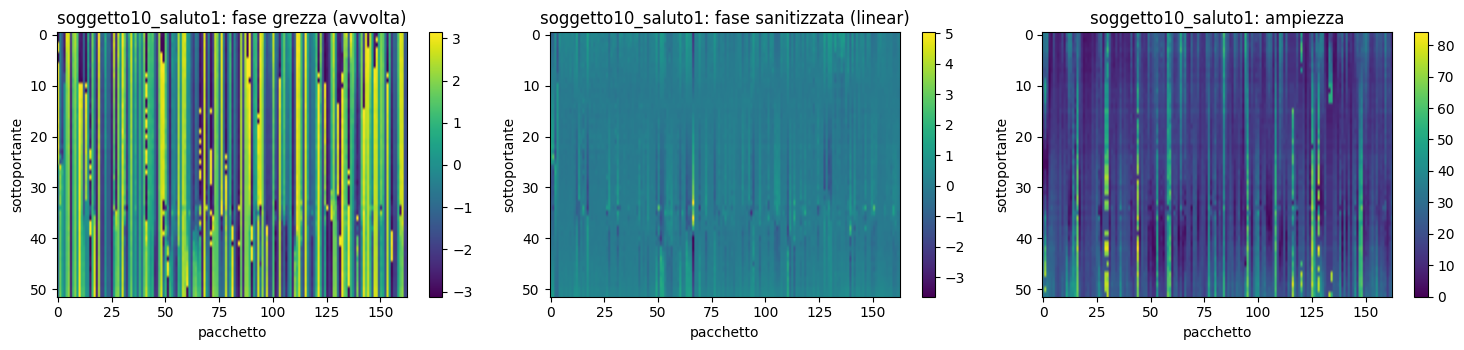

In [3]:
def phase_residual(H, mode):
    # H: [T, 52] complesso. Restituisce fase residua [T,52], pendenza per pacchetto [T], offset per pacchetto [T]
    ph = np.unwrap(np.angle(H), axis=1)                       # srotola lungo le sottoportanti
    k = np.arange(H.shape[1]).astype(float); kc = k - k.mean()
    slope = (ph * kc).sum(axis=1) / (kc ** 2).sum()           # regressione lineare per pacchetto (vettorizzata)
    icpt = ph.mean(axis=1) - slope * k.mean()
    if mode == 'linear':
        res = ph - (slope[:, None] * k[None, :] + icpt[:, None])
    elif mode == 'offset':
        res = ph - ph.mean(axis=1, keepdims=True)
    else:
        raise ValueError(mode)
    return res, slope, icpt

def zscore_fill(M, thr):
    if thr is None: return M
    mu, sd = M.mean(0), M.std(0) + 1e-12
    mask = np.abs((M - mu) / sd) > thr
    return pd.DataFrame(M).mask(mask).ffill().bfill().to_numpy()

# --- diagnostica su alcune registrazioni ---
rows = []
for r in recs[:: max(1, len(recs) // 8)][:8]:
    res, slope, icpt = phase_residual(r['H'], CFG['phase_mode'])
    ph = np.angle(r['H'])
    rows.append({'registrazione': r['rec_id'], 'std fase grezza nel tempo (rad)': ph.std(0).mean(),
                 'std offset per pacchetto': icpt.std(), 'pendenza media': slope.mean(), 'std pendenza': slope.std(),
                 'std residuo nel tempo (rad)': res.std(0).mean(), 'std profilo statico residuo': res.mean(0).std()})
print('Struttura della fase (valori tipici):')
display(pd.DataFrame(rows).set_index('registrazione').round(3))

r0 = next(r for r in recs if r['act'] == GAL)
res0, _, _ = phase_residual(r0['H'], CFG['phase_mode'])
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a, M, t in zip(ax, [np.angle(r0['H']), res0, r0['A']], ['fase grezza (avvolta)', f"fase sanitizzata ({CFG['phase_mode']})", 'ampiezza']):
    im = a.imshow(M.T, aspect='auto', cmap='viridis'); a.set_title(f"{r0['rec_id']}: {t}"); a.set_xlabel('pacchetto'); a.set_ylabel('sottoportante')
    plt.colorbar(im, ax=a)
plt.tight_layout(); plt.show()

## 4. Feature (ampiezza, fase, vuoto-sottratto) per registrazione intera

In [4]:
def amp_groups(A):
    X = A / (A.mean() + 1e-8)
    return {'static': X.mean(0), 'dyn_std': X.std(0), 'diff': np.abs(np.diff(X, axis=0)).mean(0)}

def phase_groups(Rz, slope, icpt):
    return {'ph_static': Rz.mean(0), 'ph_std': Rz.std(0), 'ph_diff': np.abs(np.diff(Rz, axis=0)).mean(0),
            # DIAGNOSTICA: dipende dall'hardware/sessione, NON dalla persona
            'ph_sto': np.array([slope.mean(), slope.std(), np.abs(np.diff(slope)).mean(),
                                np.abs(np.exp(1j * icpt).mean()), np.abs(np.angle(np.exp(1j * np.diff(icpt)))).mean()])}

def sanitized_complex(H, mode, thr):
    # campo complesso con fase sanitizzata e ampiezza normalizzata per registrazione
    res, slope, icpt = phase_residual(H, mode)
    res = zscore_fill(res, thr)
    mag = np.abs(H) / (np.abs(H).mean() + 1e-8)
    return mag * np.exp(1j * res), res, slope, icpt

def build_features(mode, thr=CFG['phase_outlier_z']):
    # canale della stanza vuota (media complessa dei pacchetti sanitizzati di tutte le registrazioni "vuoto")
    H0 = None
    if vuoto:
        Hs_v = np.concatenate([sanitized_complex(v['H'], mode, thr)[0] for v in vuoto], axis=0)
        H0 = Hs_v.mean(axis=0)
    out = defaultdict(list)
    for r in recs:
        Hs, Rz, slope, icpt = sanitized_complex(r['H'], mode, thr)
        g = amp_groups(r['A']); g.update(phase_groups(Rz, slope, icpt))
        if H0 is not None:
            D = zscore_fill(np.abs(Hs - H0[None, :]), thr)               # componente di canale non spiegata dalla stanza vuota
            g.update({'vu_static': D.mean(0), 'vu_std': D.std(0), 'vu_diff': np.abs(np.diff(D, axis=0)).mean(0)})
        for k, v in g.items(): out[k].append(v)
    return {k: np.stack(v) for k, v in out.items()}

t0 = time.time()
feat = build_features(CFG['phase_mode'])
HAS_VUOTO = 'vu_static' in feat
GROUPS = [g for g in ['static', 'dyn_std', 'diff', 'ph_static', 'ph_std', 'ph_diff', 'vu_static', 'vu_std', 'vu_diff', 'ph_sto'] if g in feat]
print(f'feature (fase: {CFG["phase_mode"]}) in {time.time() - t0:.1f}s |', {g: feat[g].shape[1] for g in GROUPS})
print('NaN/inf nelle feature:', {g: int((~np.isfinite(feat[g])).sum()) for g in GROUPS if (~np.isfinite(feat[g])).any()} or 'nessuno')

FEATURE_SETS = {
    'amp static':             ['static'],
    'amp basic':              ['static', 'dyn_std', 'diff'],
    'ph static':              ['ph_static'],
    'ph dyn':                 ['ph_std', 'ph_diff'],
    'ph all':                 ['ph_static', 'ph_std', 'ph_diff'],
    'amp static + ph static': ['static', 'ph_static'],
    'amp static + ph dyn':    ['static', 'ph_std', 'ph_diff'],
    'amp basic + ph all':     ['static', 'dyn_std', 'diff', 'ph_static', 'ph_std', 'ph_diff'],
}
if HAS_VUOTO:
    FEATURE_SETS.update({'vuoto-sub static':     ['vu_static'],
                         'vuoto-sub basic':      ['vu_static', 'vu_std', 'vu_diff'],
                         'vuoto-sub + ph all':   ['vu_static', 'vu_std', 'vu_diff', 'ph_static', 'ph_std', 'ph_diff']})
FEATURE_SETS['DIAG ph_sto (hardware)'] = ['ph_sto']
NESTED_EXCLUDE = {'DIAG ph_sto (hardware)'}                   # la diagnostica non partecipa alla selezione
XS = {n: np.concatenate([feat[g] for g in gs], axis=1) for n, gs in FEATURE_SETS.items()}
print({n: x.shape[1] for n, x in XS.items()})

feature (fase: linear) in 7.3s | {'static': 52, 'dyn_std': 52, 'diff': 52, 'ph_static': 52, 'ph_std': 52, 'ph_diff': 52, 'vu_static': 52, 'vu_std': 52, 'vu_diff': 52, 'ph_sto': 5}
NaN/inf nelle feature: nessuno
{'amp static': 52, 'amp basic': 156, 'ph static': 52, 'ph dyn': 104, 'ph all': 156, 'amp static + ph static': 104, 'amp static + ph dyn': 156, 'amp basic + ph all': 312, 'vuoto-sub static': 52, 'vuoto-sub basic': 156, 'vuoto-sub + ph all': 312, 'DIAG ph_sto (hardware)': 5}


## 5. Metriche e protocolli (come v7/v8)

In [5]:
def expected_ap_random(n, p):
    if n <= 1: return 1.0
    i = np.arange(1, n + 1)
    return float(np.sum((1.0 / i) * (1 + (i - 1) * (p - 1) / (n - 1))) / n)

def rank_metrics(q_feats, q_ids, g_feats, g_ids, exclude_self=False):
    sim = q_feats @ g_feats.T
    q_ids, g_ids = np.asarray(q_ids), np.asarray(g_ids)
    matches = q_ids[:, None] == g_ids[None, :]
    if exclude_self:
        np.fill_diagonal(sim, -np.inf); np.fill_diagonal(matches, False)
    valid = matches.sum(1) > 0
    sim, matches = sim[valid], matches[valid]
    if len(sim) == 0:
        return dict(rank1=np.nan, rank5=np.nan, mAP=np.nan, n_queries=0, chance_rank1=np.nan, chance_mAP=np.nan)
    order = np.argsort(-sim, axis=1, kind='stable')
    m = np.take_along_axis(matches, order, axis=1)
    cum = np.cumsum(m, axis=1)
    cmc = (cum > 0).mean(axis=0) * 100.0
    ap = ((cum / (np.arange(m.shape[1]) + 1)) * m).sum(axis=1) / m.sum(axis=1)
    n_gal = matches.shape[1] - (1 if exclude_self else 0); pos = matches.sum(1)
    return dict(rank1=cmc[0], rank5=cmc[min(4, len(cmc) - 1)], mAP=ap.mean() * 100.0, n_queries=len(sim),
                chance_rank1=(pos / n_gal).mean() * 100.0,
                chance_mAP=np.mean([expected_ap_random(n_gal, p) for p in pos]) * 100.0)

PROTOCOLS = ['cross', 'cross_rev', f'same_{GAL}', f'same_{PRB}']

def eval_protocols(E, sid, act):
    G, Pm = act == GAL, act == PRB
    return {'cross':       rank_metrics(E[Pm], sid[Pm], E[G],  sid[G]),
            'cross_rev':   rank_metrics(E[G],  sid[G],  E[Pm], sid[Pm]),
            f'same_{GAL}': rank_metrics(E[G],  sid[G],  E[G],  sid[G],  exclude_self=True),
            f'same_{PRB}': rank_metrics(E[Pm], sid[Pm], E[Pm], sid[Pm], exclude_self=True)}

def l2(Z): return Z / (np.linalg.norm(Z, axis=1, keepdims=True) + 1e-12)

def aggregate_folds(res_list):
    out = {}
    for k in PROTOCOLS:
        w = np.array([r[k]['n_queries'] for r in res_list], float)
        for m in ['rank1', 'mAP', 'chance_rank1', 'chance_mAP']:
            v = np.array([r[k][m] for r in res_list]); out[(k, m)] = float((w * v).sum() / w.sum())
        for m in ['rank1', 'mAP']:
            out[(k, m + '_std')] = float(np.std([r[k][m] for r in res_list]))
    return out

def mean_map(res): return float(np.mean([res[k]['mAP'] for k in PROTOCOLS]))

REDUCERS = {'LDA': ('lda', None), 'PCA20+LDA': ('pca_lda', 20), 'cos': ('cos', None)}

def embed_config(X, train_idx, reducer):
    kind, n = reducer
    mu, sd = X[train_idx].mean(0), X[train_idx].std(0) + 1e-8
    Z = (X - mu) / sd
    if kind == 'cos': return l2(Z)
    if kind == 'pca_lda':
        nc = int(min(n, Z.shape[1], len(train_idx) - 1))
        Z = PCA(n_components=nc, random_state=0).fit(Z[train_idx]).transform(Z)
    lda = LinearDiscriminantAnalysis(solver='eigen', shrinkage='auto').fit(Z[train_idx], rec_sid[train_idx])
    return l2(lda.transform(Z))

def eval_cfg(X, reducer, train_idx, test_idx):
    Z = embed_config(X, train_idx, reducer)
    return eval_protocols(Z[test_idx], rec_sid[test_idx], rec_act[test_idx])

def run_cv(X, reducer):
    return [eval_cfg(X, reducer, tr, te) for tr, te in folds]

## 6. Griglia (insiemi di feature × riduttore) e selezione annidata

In [6]:
t0 = time.time()
grid_res = {(fs, rd): run_cv(XS[fs], REDUCERS[rd]) for fs in FEATURE_SETS for rd in REDUCERS}
print(f'griglia {len(grid_res)} configurazioni in {time.time() - t0:.1f}s')

rows = []
for (fs, rd), res in grid_res.items():
    a = aggregate_folds(res)
    rows.append({'feature': fs, 'riduzione': rd, 'dim': XS[fs].shape[1],
                 'mAP media4': np.mean([a[(k, 'mAP')] for k in PROTOCOLS]),
                 'cross mAP': a[('cross', 'mAP')], 'same mAP': np.mean([a[(f'same_{GAL}', 'mAP')], a[(f'same_{PRB}', 'mAP')]]),
                 'cross R1': a[('cross', 'rank1')], 'same R1': np.mean([a[(f'same_{GAL}', 'rank1')], a[(f'same_{PRB}', 'rank1')]])})
grid = pd.DataFrame(rows)
ch = aggregate_folds(next(iter(grid_res.values())))
print('Chance mAP media4: %.1f' % np.mean([ch[(k, 'chance_mAP')] for k in PROTOCOLS]))
print('=== mAP media4 (%) ===')
display(grid.pivot(index='feature', columns='riduzione', values='mAP media4').loc[list(FEATURE_SETS), list(REDUCERS)].round(1))

# --- selezione ANNIDATA ---
def inner_splits(train_idx, k, seed):
    ids = sorted(set(rec_sid[train_idx]), key=natural_key)
    perm = np.random.RandomState(seed).permutation(len(ids))
    for chunk in np.array_split(perm, k):
        mask = np.isin(rec_sid[train_idx], [ids[i] for i in chunk])
        yield train_idx[~mask], train_idx[mask]

cand = [k for k in grid_res if k[0] not in NESTED_EXCLUDE]
t0 = time.time(); nested_res, chosen = [], []
for f, (tr, te) in enumerate(folds):
    splits = list(inner_splits(tr, CFG['inner_folds'], CFG['seed'] + f))
    scores = {key: np.mean([mean_map(eval_cfg(XS[key[0]], REDUCERS[key[1]], itr, ite)) for itr, ite in splits]) for key in cand}
    best = max(scores, key=scores.get); chosen.append((best, scores[best])); nested_res.append(grid_res[best][f])
print(f'selezione annidata in {time.time() - t0:.1f}s. Configurazioni scelte per fold:')
for f, (b, s) in enumerate(chosen): print(f'  fold {f + 1}: {b[0]} | {b[1]}   (mAP interna {s:.1f})')

best_fixed = max(cand, key=lambda k: np.mean([aggregate_folds(grid_res[k])[(p, 'mAP')] for p in PROTOCOLS]))

def results_table(store):
    rows = []; ch = aggregate_folds(next(iter(store.values())))
    rows.append({'metodo': 'CHANCE', **{f'{k} {m}': ch[(k, key)] for k in PROTOCOLS for m, key in [('R1', 'chance_rank1'), ('mAP', 'chance_mAP')]}})
    for name, res in store.items():
        a = aggregate_folds(res)
        rows.append({'metodo': name, **{f'{k} {m}': a[(k, key)] for k in PROTOCOLS for m, key in [('R1', 'rank1'), ('mAP', 'mAP')]}})
    return pd.DataFrame(rows).set_index('metodo').round(1)

store = {
    'amp static + LDA  (v8)':                 grid_res[('amp static', 'LDA')],
    'amp basic + LDA':                        grid_res[('amp basic', 'LDA')],
    'ph all + LDA':                           grid_res[('ph all', 'LDA')],
    'amp basic + ph all + LDA':               grid_res[('amp basic + ph all', 'LDA')],
    f'Miglior config fissa [{best_fixed[0]} | {best_fixed[1]}] (ottimistica)': grid_res[best_fixed],
    'Selezione ANNIDATA (onesta)':            nested_res,
    'DIAG: ph_sto (hardware) + LDA':          grid_res[('DIAG ph_sto (hardware)', 'LDA')],
}
if HAS_VUOTO:
    store['vuoto-sub basic + LDA'] = grid_res[('vuoto-sub basic', 'LDA')]
print('\n=== RISULTATI (Rank-1 % / mAP %) ===')
display(results_table(store))

griglia 36 configurazioni in 13.8s
Chance mAP media4: 14.4
=== mAP media4 (%) ===


riduzione,LDA,PCA20+LDA,cos
feature,,,
amp static,34.3,29.8,29.6
amp basic,32.7,30.1,28.0
ph static,34.7,28.8,29.6
ph dyn,29.9,25.1,29.6
ph all,38.4,34.9,33.6
amp static + ph static,38.2,33.2,32.4
amp static + ph dyn,38.7,35.1,35.2
amp basic + ph all,38.1,35.2,31.5
vuoto-sub static,29.1,28.3,24.7


selezione annidata in 24.4s. Configurazioni scelte per fold:
  fold 1: ph all | LDA   (mAP interna 39.0)
  fold 2: amp static + ph dyn | LDA   (mAP interna 38.3)
  fold 3: amp static + ph static | LDA   (mAP interna 37.1)
  fold 4: amp static + ph dyn | LDA   (mAP interna 42.4)

=== RISULTATI (Rank-1 % / mAP %) ===


,cross R1,cross mAP,cross_rev R1,cross_rev mAP,same_saluto R1,same_saluto mAP,same_tpose R1,same_tpose mAP
metodo,,,,,,,,
CHANCE,9.1,15.1,9.1,15.1,7.4,13.7,7.4,13.7
amp static + LDA (v8),30.0,30.0,26.4,28.6,48.6,41.6,40.0,36.9
amp basic + LDA,29.1,28.2,25.5,27.2,49.1,42.0,37.7,33.3
ph all + LDA,31.8,33.1,33.2,32.6,50.5,46.5,41.4,41.2
amp basic + ph all + LDA,37.3,33.5,33.2,32.4,53.6,48.0,40.0,38.4
Miglior config fissa [amp static + ph dyn | LDA] (ottimistica),32.3,34.0,33.6,34.2,46.8,45.5,44.1,41.0
Selezione ANNIDATA (onesta),31.4,33.0,30.5,32.9,50.5,45.9,40.5,39.1
DIAG: ph_sto (hardware) + LDA,15.0,20.2,15.5,20.7,15.5,20.9,22.7,22.5
vuoto-sub basic + LDA,20.9,24.2,24.5,25.5,45.9,38.0,34.5,31.7


## 7. Ablazione per gruppo (LDA)

In [7]:
groups_legit = [g for g in GROUPS if g != 'ph_sto']
abl_rows = []
combos = [(g, [g]) for g in GROUPS] + [('TUTTI (senza ph_sto)', groups_legit)] + [(f'tutti - {g}', [x for x in groups_legit if x != g]) for g in groups_legit]
for name, gs in combos:
    X = np.concatenate([feat[g] for g in gs], axis=1)
    a = aggregate_folds(run_cv(X, REDUCERS['LDA']))
    abl_rows.append({'gruppi': name, 'dim': X.shape[1],
                     'mAP media4': np.mean([a[(k, 'mAP')] for k in PROTOCOLS]),
                     'cross mAP': a[('cross', 'mAP')], 'same mAP': np.mean([a[(f'same_{GAL}', 'mAP')], a[(f'same_{PRB}', 'mAP')]]),
                     'cross R1': a[('cross', 'rank1')]})
print('Chance mAP media4: %.1f' % np.mean([ch[(k, 'chance_mAP')] for k in PROTOCOLS]))
display(pd.DataFrame(abl_rows).set_index('gruppi').round(1))

Chance mAP media4: 14.4


,dim,mAP media4,cross mAP,same mAP,cross R1
gruppi,,,,,
static,52,34.3,30.0,39.2,30.0
dyn_std,52,25.9,22.5,29.7,20.5
diff,52,25.2,22.3,28.1,16.8
ph_static,52,34.7,31.2,38.6,27.7
ph_std,52,29.9,27.4,32.8,25.0
ph_diff,52,29.8,27.0,32.9,22.7
vu_static,52,29.1,25.3,32.8,25.5
vu_std,52,26.7,23.1,30.4,19.1
vu_diff,52,25.9,22.0,29.4,16.4


## 8. Deriva con il numero soggetto e localizzazione degli errori

Stesso test di v8 (permutazioni dell'ordine dei soggetti), ora su **tutti** i gruppi, fase e vuoto-sottratto compresi. Assunzione: la numerazione segue l'ordine di acquisizione.
`ph_sto` è l'indicatore hardware: se *lui* mostra deriva forte, il canale/dispositivo cambia nel tempo e ogni feature legata a quel cambiamento è sospetta.

In [8]:
def subj_number(s):
    m = re.search(r'(\d+)$', s); return int(m.group(1)) if m else None

subs = sorted(set(rec_sid), key=natural_key)
nums_raw = [subj_number(s) for s in subs]
if not all(n is not None for n in nums_raw):
    print('Nomi soggetto senza numero finale: salto il controllo di deriva.')
else:
    order = np.argsort(nums_raw); subs = [subs[i] for i in order]; nums = np.array([nums_raw[i] for i in order])
    num_of = dict(zip(subs, nums)); n_sub = len(subs)
    lag = np.abs(nums[:, None] - nums[None, :]); iu = np.triu_indices(n_sub, 1)
    rl = rankdata(lag[iu]); rl = rl - rl.mean()
    B = CFG['drift_perms']; prng = np.random.RandomState(CFG['seed'])
    perms = [np.arange(n_sub)] + [prng.permutation(n_sub) for _ in range(B)]
    big = np.eye(n_sub) * 1e9

    def drift_stats(D):
        rho, nn = [], []
        for p in perms:
            Dp = D[np.ix_(p, p)]
            rd = rankdata(Dp[iu]); rd = rd - rd.mean()
            rho.append((rl * rd).sum() / np.sqrt((rl ** 2).sum() * (rd ** 2).sum()))
            nn.append(lag[np.arange(n_sub), np.argmin(Dp + big, axis=1)].mean())
        rho, nn = np.array(rho), np.array(nn)
        return rho[0], (1 + (rho[1:] >= rho[0]).sum()) / (1 + B), nn[0], nn[1:].mean(), (1 + (nn[1:] <= nn[0]).sum()) / (1 + B)

    rows, D_by_group = [], {}
    for g in GROUPS:
        Xg = feat[g]; Zg = (Xg - Xg.mean(0)) / (Xg.std(0) + 1e-8)
        M = np.stack([Zg[rec_sid == s].mean(0) for s in subs]); M = l2(M - M.mean(0))
        D = 1 - M @ M.T; D_by_group[g] = D
        rho, p_rho, nn_obs, nn_null, p_nn = drift_stats(D)
        rows.append({'gruppo': g, 'Spearman(lag, dist)': rho, 'p (deriva)': p_rho,
                     'vicino piu simile |Δnum|': nn_obs, 'atteso a caso': nn_null, 'p (vicini)': p_nn})
    thr = 0.05 / len(GROUPS)
    drift = pd.DataFrame(rows).set_index('gruppo').round(3)
    drift['significativo (Bonferroni)'] = (drift['p (deriva)'] < thr) | (drift['p (vicini)'] < thr)
    print(f'{n_sub} soggetti | {B} permutazioni | soglia di Bonferroni su {len(GROUPS)} gruppi: p < {thr:.4f}')
    display(drift)

    bins = [1, 2, 4, 8, 16, 32, 100]
    lag_tab = [{'gruppo': g, **{f'lag {a}-{b - 1}': D_by_group[g][iu][(lag[iu] >= a) & (lag[iu] < b)].mean() for a, b in zip(bins[:-1], bins[1:])}} for g in GROUPS]
    print('Distanza media fra profili per distanza in numero soggetto (cresce con il lag = deriva):')
    display(pd.DataFrame(lag_tab).set_index('gruppo').round(3))

    def wrong_top1(E, sid, act, protocol):
        G, Pm = act == GAL, act == PRB
        if protocol == 'cross': q_idx, g_idx, ex = np.where(Pm)[0], np.where(G)[0], False
        else:                   q_idx, g_idx, ex = np.where(G)[0], np.where(G)[0], True
        sim = E[q_idx] @ E[g_idx].T
        if ex: sim[np.arange(len(q_idx)), np.arange(len(q_idx))] = -np.inf
        top = g_idx[np.argmax(sim, axis=1)]
        ids_here = sorted(set(sid[q_idx]), key=natural_key); obs, exp = [], []
        for qi, ti in zip(q_idx, top):
            if sid[qi] != sid[ti]:
                obs.append(abs(num_of[sid[qi]] - num_of[sid[ti]]))
                exp.append(np.mean([abs(num_of[sid[qi]] - num_of[s]) for s in ids_here if s != sid[qi]]))
        return obs, exp

    loc_rows = []; brng = np.random.RandomState(0)
    for fs in ['amp static', 'ph all', 'amp basic + ph all'] + (['vuoto-sub basic'] if HAS_VUOTO else []):
        for protocol in ['cross', f'same_{GAL}']:
            obs, exp = [], []
            for tr, te in folds:
                E = embed_config(XS[fs], tr, REDUCERS['LDA'])[te]
                o, e = wrong_top1(E, rec_sid[te], rec_act[te], protocol); obs += o; exp += e
            d = np.array(obs) - np.array(exp)
            if len(d) == 0:                                    # nessun errore: niente da localizzare
                loc_rows.append({'metodo': f'{fs}+LDA', 'protocollo': protocol, 'top-1 sbagliati': 0}); continue
            boot = [brng.choice(d, len(d)).mean() for _ in range(2000)]
            loc_rows.append({'metodo': f'{fs}+LDA', 'protocollo': protocol, 'top-1 sbagliati': len(d),
                             '|Δnum| osservato': np.mean(obs), 'atteso a caso': np.mean(exp), 'differenza': d.mean(),
                             'IC95': f'[{np.percentile(boot, 2.5):.1f}, {np.percentile(boot, 97.5):.1f}]'})
    print('Top-1 SBAGLIATI: |Δ numero soggetto| fra query e identità restituita (differenza < 0 con IC95 che esclude 0 = errori fra soggetti vicini):')
    display(pd.DataFrame(loc_rows).set_index(['metodo', 'protocollo']).round(2))

44 soggetti | 2000 permutazioni | soglia di Bonferroni su 10 gruppi: p < 0.0050


,"Spearman(lag, dist)",p (deriva),vicino piu simile |Δnum|,atteso a caso,p (vicini),significativo (Bonferroni)
gruppo,,,,,,
static,0.010,0.279,11.455,14.997,0.020,False
dyn_std,0.109,0.011,11.432,15.002,0.020,False
diff,0.213,0.001,9.568,14.946,0.001,True
ph_static,0.095,0.012,10.273,15.015,0.003,True
ph_std,0.304,0.000,10.659,15.029,0.002,True
ph_diff,0.304,0.000,10.068,15.014,0.001,True
vu_static,0.231,0.000,10.841,15.013,0.008,True
vu_std,0.104,0.010,12.795,14.997,0.099,False
vu_diff,0.174,0.001,10.886,15.026,0.009,True


Distanza media fra profili per distanza in numero soggetto (cresce con il lag = deriva):


,lag 1-1,lag 2-3,lag 4-7,lag 8-15,lag 16-31,lag 32-99
gruppo,,,,,,
static,1.041,0.870,0.964,1.134,0.985,1.043
dyn_std,0.873,0.843,0.965,1.090,0.975,1.357
diff,0.868,0.823,0.833,1.007,1.068,1.555
ph_static,0.892,0.877,0.993,1.063,0.992,1.243
ph_std,0.633,0.654,0.642,0.828,1.026,1.511
ph_diff,0.614,0.656,0.649,0.839,1.029,1.495
vu_static,0.841,0.847,0.847,0.960,1.113,1.471
vu_std,0.859,0.875,0.963,1.086,0.991,1.254
vu_diff,0.869,0.846,0.885,1.032,1.027,1.418


Top-1 SBAGLIATI: |Δ numero soggetto| fra query e identità restituita (differenza < 0 con IC95 che esclude 0 = errori fra soggetti vicini):


top-1 sbagliati  |Δnum| osservato  atteso a caso  differenza          IC95
metodo                 protocollo                                                                             
amp static+LDA         cross                    154             12.79          15.43       -2.64  [-4.1, -1.3]
                       same_saluto              113             16.25          15.61        0.64   [-1.1, 2.4]
ph all+LDA             cross                    150             11.77          15.08       -3.31  [-4.8, -1.8]
                       same_saluto              109             12.91          15.20       -2.29  [-4.1, -0.6]
amp basic + ph all+LDA cross                    138             11.57          15.35       -3.78  [-5.3, -2.2]
                       same_saluto              102             14.15          15.51       -1.36   [-3.3, 0.7]
vuoto-sub basic+LDA    cross                    174             13.10          15.37       -2.27  [-3.8, -0.8]
                       same_saluto              119             12.87          14.85       -1.98  [-3.7, -0.2]

## 9. "Vuoto": perché la sottrazione costante non basta

Sottrarre alle ampiezze (o ai profili statici) **lo stesso** profilo della stanza vuota è una traslazione costante di ogni feature. Le feature vengono standardizzate (media/deviazione stimate sul training) prima di cosine/LDA, quindi la traslazione si cancella: il risultato deve essere **identico**. Lo verifico, poi guardo cosa dice il vuoto-sottratto *complesso* (§6).

In [9]:
if not vuoto:
    print('Nessuna registrazione "vuoto" trovata.')
else:
    A_v = np.concatenate([v['A'] for v in vuoto], axis=0)
    vu_static = (A_v / (A_v.mean() + 1e-8)).mean(0)                 # profilo statico della stanza vuota
    X_shift = XS['amp static'] - vu_static[None, :]                  # sottrazione costante
    a0 = aggregate_folds(run_cv(XS['amp static'], REDUCERS['LDA']))
    a1 = aggregate_folds(run_cv(X_shift, REDUCERS['LDA']))
    diff = max(abs(a0[(k, m)] - a1[(k, m)]) for k in PROTOCOLS for m in ['rank1', 'mAP'])
    print(f'Differenza massima (Rank-1/mAP, punti %) fra "amp static" e "amp static - vuoto": {diff:.6f}  (attesa ~0)')

    n_v = len(vuoto)
    print(f'\nRegistrazioni "vuoto": {n_v} ({sum(v["A"].shape[0] for v in vuoto)} pacchetti in totale).')
    if n_v < 4:
        print('Con così poche registrazioni il vuoto è UN solo riferimento nel tempo: può togliere il contributo medio della stanza, '
              'ma non la sua variazione fra un soggetto e l\'altro (deriva). Per correggere la deriva servirebbe un "vuoto" '
              'registrato vicino nel tempo a ciascun soggetto (o a blocchi).')
    a = aggregate_folds(grid_res[('vuoto-sub basic', 'LDA')]); b = aggregate_folds(grid_res[('amp basic', 'LDA')])
    print('\nvuoto-sottratto complesso vs ampiezza (LDA), mAP media4: %.1f vs %.1f' % (
        np.mean([a[(k, 'mAP')] for k in PROTOCOLS]), np.mean([b[(k, 'mAP')] for k in PROTOCOLS])))

Differenza massima (Rank-1/mAP, punti %) fra "amp static" e "amp static - vuoto": 0.000000  (attesa ~0)

Registrazioni "vuoto": 1 (183 pacchetti in totale).
Con così poche registrazioni il vuoto è UN solo riferimento nel tempo: può togliere il contributo medio della stanza, ma non la sua variazione fra un soggetto e l'altro (deriva). Per correggere la deriva servirebbe un "vuoto" registrato vicino nel tempo a ciascun soggetto (o a blocchi).

vuoto-sottratto complesso vs ampiezza (LDA), mAP media4: 29.8 vs 32.7


## 10. Fase: `linear` vs `offset`

In [10]:
alt = 'offset' if CFG['phase_mode'] == 'linear' else 'linear'
feat_alt = build_features(alt)
rows = []
for name, gs in [('ph all', ['ph_static', 'ph_std', 'ph_diff']), ('ph dyn', ['ph_std', 'ph_diff']),
                 ('amp basic + ph all', ['static', 'dyn_std', 'diff', 'ph_static', 'ph_std', 'ph_diff'])]:
    for mode, ft in [(CFG['phase_mode'], feat), (alt, feat_alt)]:
        a = aggregate_folds(run_cv(np.concatenate([ft[g] for g in gs], axis=1), REDUCERS['LDA']))
        rows.append({'feature': name, 'fase': mode, 'mAP media4': np.mean([a[(k, 'mAP')] for k in PROTOCOLS]),
                     'cross R1': a[('cross', 'rank1')], 'cross mAP': a[('cross', 'mAP')],
                     'same R1': np.mean([a[(f'same_{GAL}', 'rank1')], a[(f'same_{PRB}', 'rank1')]])})
display(pd.DataFrame(rows).set_index(['feature', 'fase']).round(1))

mAP media4  cross R1  cross mAP  same R1
feature            fase                                            
ph all             linear        38.4      31.8       33.1     45.9
                   offset        38.5      34.1       33.7     46.8
ph dyn             linear        29.9      22.3       26.9     33.2
                   offset        29.6      20.9       26.9     33.9
amp basic + ph all linear        38.1      37.3       33.5     46.8
                   offset        36.1      31.8       31.6     44.5

## 11. Esporta le fasi sanitizzate (per DatasetGeneration / GNN)

In [11]:
if CFG['export_phase_csv']:
    out_dir = os.path.join(CFG['output_folder'], 'CSV', 'sanitized_phases', f"{CFG['phase_mode']}_phases")
    os.makedirs(out_dir, exist_ok=True)
    for r in recs:
        res, _, _ = phase_residual(r['H'], CFG['phase_mode'])
        res = zscore_fill(res, CFG['phase_outlier_z'])
        df = pd.DataFrame(res, columns=range(res.shape[1])); df['timestamp'] = np.arange(len(df))
        df.to_csv(os.path.join(out_dir, r['rec_id'] + '.csv'), index=False)
    print(f'{len(recs)} file di fase sanitizzata scritti in {out_dir}  (stesso formato dei CSV delle ampiezze: 52 colonne + timestamp)')
else:
    print('export_phase_csv=False')

440 file di fase sanitizzata scritti in ./output/CSV/sanitized_phases/linear_phases  (stesso formato dei CSV delle ampiezze: 52 colonne + timestamp)


## 12. Come leggere i risultati

* **§6 / §7:** `ph all` e `amp basic + ph all` contro `amp static` (34.3 mAP media in v8). Se la fase da sola o combinata supera chiaramente l'ampiezza, è la leva giusta anche per la GNN; se `ph_static` è il gruppo forte, la fase porta l'informazione "statica" (forma del corpo/posizione), se lo sono `ph_std`/`ph_diff`, porta la dinamica del movimento.
* **Diagnostica `ph_sto`:** se da sola classifica sopra la chance, l'hardware/sessione identifica già il soggetto (le registrazioni di uno stesso soggetto sono vicine nel tempo): è un bias, non identità. Nel test di deriva, un `ph_sto` fortemente correlato con il numero soggetto lo conferma.
* **§8:** gruppi con deriva significativa dopo Bonferroni contengono una componente di sessione; confronta quali di essi guadagnano accuratezza.
* **§9:** il vuoto-sottratto complesso è l'unico modo non banale di sfruttare una singola registrazione di stanza vuota. Se non migliora, serve un vuoto per soggetto/blocco (da chiedere/registrare).
* **§10:** se `offset` e `linear` sono simili, la scelta non è critica; se `offset` è migliore, la pendenza lineare contiene identità (ritardo di percorso) e conviene non toglierla.
* Con 220 query per protocollo e fold std di diversi punti, differenze < 3 punti non sono significative.